# Soil photos: EDA

We check the photos, soil curves, scale, and data splits. We use CPU only.

Score: [Kaggle evaluation](https://www.kaggle.com/competitions/soil-grain-size-from-photos/overview/evaluation).

In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""

from pathlib import Path
import hashlib
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 42
DATA_DIR = next(Path("/kaggle/input").rglob("Training_labels_updated.csv")).parent
WORK_DIR = Path("/kaggle/working/soil_eda")
WORK_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 15)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Data:", DATA_DIR)

Python: 3.13.15 | NumPy: 2.1.3 | pandas: 2.3.3
Data: /kaggle/input/competitions/soil-grain-size-from-photos
Device: CPU


## 1. Read the tables

One label row is one soil sample. Many photos can share this row.
The target is the percent of soil below each size, in mm.

In [2]:
labels = pd.read_csv(DATA_DIR / "Training_labels_updated.csv")
submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
scale = pd.read_csv(DATA_DIR / "ppm_updated.csv")
labels["sample_id"] = labels["sample_id"].str.strip()
submission["sample_id"] = submission["sample_id"].str.strip()

targets = labels.columns.drop("sample_id").tolist()
sieves = np.array(targets, dtype=float)
log_sieves = np.log10(sieves)
y = labels[targets].to_numpy(float)

assert targets == submission.columns.drop("sample_id").tolist()
assert len(targets) == 11 and np.all(np.diff(sieves) > 0)
display(labels.head(3))
display(scale)
print("Train samples:", len(labels), "| Test samples:", len(submission))

,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,F827,9.4904,19.3892,47.6257,89.5554,99.8965,99.9896,100.0000,100.0000,100.0000,100.0,100.0
1,G190,5.2076,10.2425,23.7537,50.3113,75.8311,85.7233,90.9898,94.8969,98.5814,100.0,100.0
2,H030,6.7833,10.9091,19.0599,37.3235,66.8349,96.4965,97.9530,99.5691,100.0000,100.0,100.0


,phone,camera,width,height,ppm
0,iPhone 14,iPhone 14,4032,3024,13.942
1,iPhone 16,iPhone 16,5712,4284,19.525
2,Motorola Edge,motorola edge 20,4000,1800,11.492
3,Motorola Edge 60 Fusion,Motorola Edge 60 fusion,4096,2304,12.465
4,Samsung A52,SM-A525F,9248,6936,26.330


Train samples: 24 | Test samples: 10


In [3]:
checks = pd.Series({
    "Missing label values": int(labels.isna().sum().sum()),
    "Repeated train sample IDs": int(labels["sample_id"].duplicated().sum()),
    "Repeated test sample IDs": int(submission["sample_id"].duplicated().sum()),
    "Non-finite target values": int((~np.isfinite(y)).sum()),
    "Values outside 0 to 100": int(((y < 0) | (y > 100)).sum()),
    "Curves that go down": int((np.diff(y, axis=1) < -1e-6).any(axis=1).sum()),
    "Curves that do not end at 100": int((~np.isclose(y[:, -1], 100)).sum()),
    "Sample IDs in both sets": len(set(labels.sample_id) & set(submission.sample_id)),
}, name="count")
display(checks.to_frame())
assert checks.eq(0).all()
print("The test CSV is a template, not test labels.")
print("Its last column must be set to 100 in a real submission.")

,count
Missing label values,0
Repeated train sample IDs,0
Repeated test sample IDs,0
Non-finite target values,0
Values outside 0 to 100,0
Curves that go down,0
Curves that do not end at 100,0
Sample IDs in both sets,0


The test CSV is a template, not test labels.
Its last column must be set to 100 in a real submission.


## 2. Match photos and samples

We read photo sizes and camera names. We also check file headers and exact file copies.
We use EXIF for test cameras. We use the file name when EXIF is empty.

In [4]:
def name_key(text):
    # German names can use either an umlaut or two letters.
    text = text.lower().replace("ä", "ae").replace("ö", "oe").replace("ü", "ue").replace("ß", "ss")
    return re.sub(r"[^a-z0-9]", "", text)

train_ids = set(labels.sample_id)
test_ids = {name_key(sample): sample for sample in submission.sample_id}
phone_names = {name_key(phone): phone for phone in scale.phone}
camera_names = {name_key(camera): phone for camera, phone in zip(scale.camera, scale.phone)}

rows = []
header_errors = []
for path in sorted(DATA_DIR.rglob("*")):
    if path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue
    is_train = "Training-All_Photos_updated" in path.parts
    if is_train:
        match = re.search(r"_([A-Z]\d{3})_", path.stem)
        sample_id = match.group(1) if match else None
    else:
        sample_name = "HPC_" + path.stem.split("_HPC_", 1)[-1]
        sample_name = re.sub(r"\s*\(\d+\)$", "", sample_name)
        sample_id = test_ids.get(name_key(sample_name))
    try:
        with Image.open(path) as image:
            width, height = image.size
            camera = str(image.getexif().get(272, "")).strip("\x00 ")
            image.verify()
    except (OSError, ValueError) as error:
        header_errors.append((path.name, str(error)))
        continue
    device = camera_names.get(name_key(camera))
    if device is None and is_train and sample_id:
        device = phone_names.get(name_key(path.stem.split("_" + sample_id)[0]))
    with path.open("rb") as file:
        file_hash = hashlib.file_digest(file, "sha256").hexdigest()
    rows.append({"path": str(path), "photo": path.name, "sample_id": sample_id,
                 "split": "train" if is_train else "test", "device": device,
                 "width": width, "height": height, "sha256": file_hash})

photos = pd.DataFrame(rows)
assert not header_errors, header_errors
assert photos[["sample_id", "device"]].notna().all().all()
assert set(photos.query("split == 'train'").sample_id) == train_ids
assert set(photos.query("split == 'test'").sample_id) == set(submission.sample_id)
print("Readable photo headers:", len(photos))
print("Unmatched photos:", photos.sample_id.isna().sum())
print("Exact file copies:", photos.sha256.duplicated().sum())
print("Hashes find exact copies only. Similar photos can still be present.")

Readable photo headers: 162
Unmatched photos: 0
Exact file copies: 0
Hashes find exact copies only. Similar photos can still be present.


,samples,photos,min_photos,median_photos,max_photos
split,,,,,
test,10,35,3,3.0,5
train,24,127,3,5.0,8


split,test,train
device,,
Motorola Edge,0,69
Motorola Edge 60 Fusion,0,3
Samsung A52,0,55
iPhone 14,14,0
iPhone 16,21,0


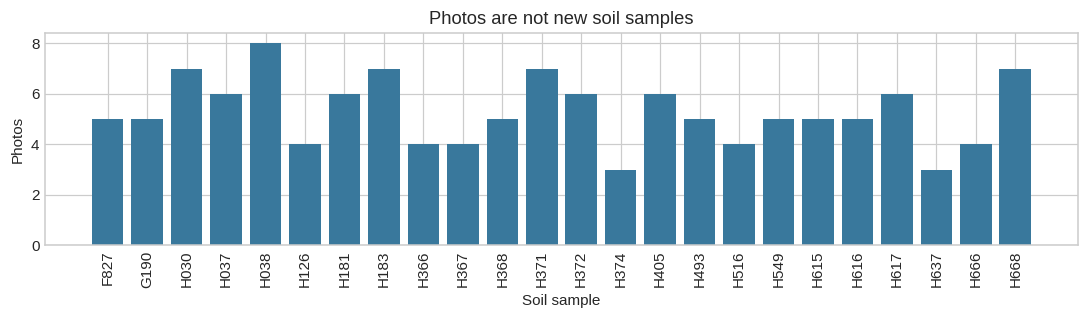

In [5]:
photo_counts = photos.groupby(["split", "sample_id"]).size().rename("photos").reset_index()
summary = photo_counts.groupby("split").agg(
    samples=("sample_id", "size"), photos=("photos", "sum"),
    min_photos=("photos", "min"), median_photos=("photos", "median"), max_photos=("photos", "max")
)
display(summary)
display(pd.crosstab(photos.device, photos.split))

train_counts = photo_counts.query("split == 'train'").sort_values("sample_id")
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(train_counts.sample_id, train_counts.photos, color="#39789c")
ax.set(xlabel="Soil sample", ylabel="Photos", title="Photos are not new soil samples")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()

## 3. Check the physical scale

PPM means pixels per mm. The scale table gives camera sizes.
Many train photos are smaller than these sizes.

We estimate new PPM from the resize ratio. We assume the photo was resized with no crop.
This is an estimate. Check it with a ruler before training.

photos  min_mp  max_mp  table_ppm  ppm_est  \
split device                                                                
test  iPhone 14                    14   12.19   12.19      13.94    13.94   
      iPhone 16                    21   24.47   24.47      19.52    19.52   
train Motorola Edge                69    1.15    1.15      11.49     4.60   
      Motorola Edge 60 Fusion       3    9.44    9.44      12.46    12.46   
      Samsung A52                  55    1.92    1.92      26.33     4.55   

                               short_side_mm  
split device                                  
test  iPhone 14                       216.90  
      iPhone 16                       219.41  
train Motorola Edge                   156.63  
      Motorola Edge 60 Fusion         184.84  
      Samsung A52                     263.51

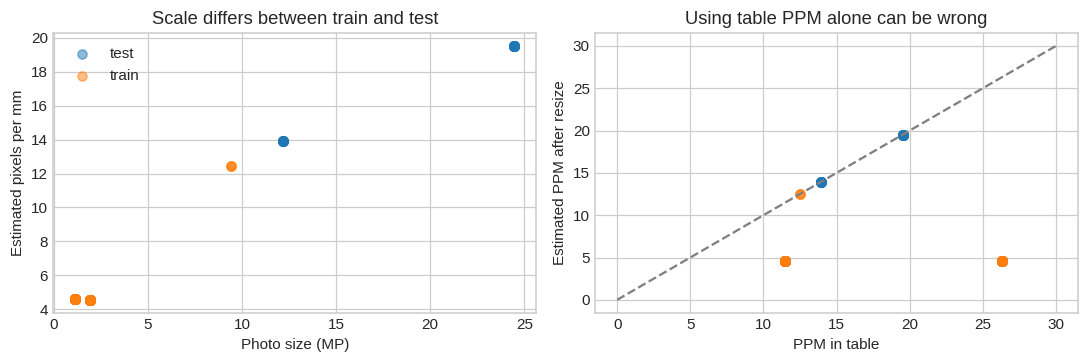

In [6]:
photos = photos.merge(
    scale.rename(columns={"phone": "device", "width": "camera_width", "height": "camera_height", "ppm": "camera_ppm"}),
    on="device", how="left", validate="many_to_one"
)
photos["resize_x"] = photos[["width", "height"]].max(axis=1) / photos[["camera_width", "camera_height"]].max(axis=1)
photos["resize_y"] = photos[["width", "height"]].min(axis=1) / photos[["camera_width", "camera_height"]].min(axis=1)
photos["ppm_est"] = photos.camera_ppm * (photos.resize_x + photos.resize_y) / 2
photos["megapixels"] = photos.width * photos.height / 1e6
photos["short_side_mm"] = photos[["width", "height"]].min(axis=1) / photos.ppm_est
assert (abs(photos.resize_x / photos.resize_y - 1) < 0.01).all()
assert photos.ppm_est.gt(0).all()

display(photos.groupby(["split", "device"]).agg(
    photos=("photo", "size"), min_mp=("megapixels", "min"), max_mp=("megapixels", "max"),
    table_ppm=("camera_ppm", "first"), ppm_est=("ppm_est", "median"),
    short_side_mm=("short_side_mm", "median")
).round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for split, group in photos.groupby("split"):
    axes[0].scatter(group.megapixels, group.ppm_est, label=split, alpha=0.5)
axes[0].set(xlabel="Photo size (MP)", ylabel="Estimated pixels per mm", title="Scale differs between train and test")
axes[0].legend()
for split, group in photos.groupby("split"):
    axes[1].scatter(group.camera_ppm, group.ppm_est, label=split, alpha=0.5)
axes[1].plot([0, 30], [0, 30], "--", color="grey")
axes[1].set(xlabel="PPM in table", ylabel="Estimated PPM after resize", title="Using table PPM alone can be wrong")
fig.tight_layout()
plt.show()

## 4. Look at fine and coarse soils

The curves go up from 0 to 100. A curve near the left has more small grains.
We use three simple groups to help make balanced folds. These are not full soil classes.

,samples,median_fines_pct
soil_group,,
fine,7,69.76
gravel,11,8.69
sand,6,31.25


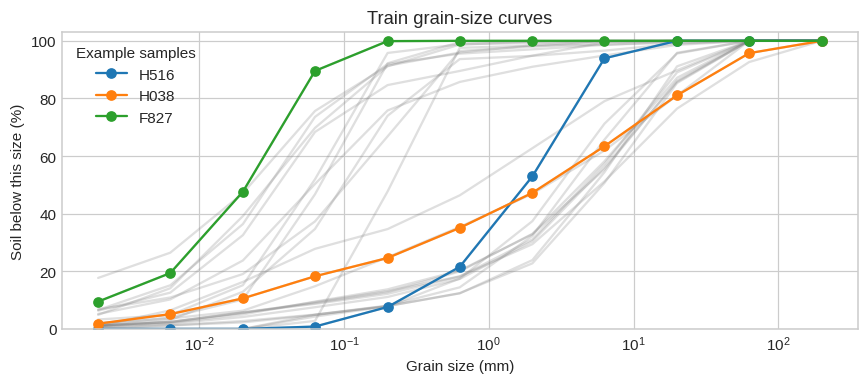

In [ ]:
labels["soil_group"] = np.where(labels["0.063"] >= 50, "fine", np.where(labels["2"] >= 50, "sand", "gravel"))
display(labels.groupby("soil_group").agg(samples=("sample_id", "size"), median_fines_pct=("0.063", "median")).round(2))

order = labels.sort_values("0.063").index.to_numpy()
example_indices = order[[0, len(order) // 2, -1]]
example_ids = labels.loc[example_indices, "sample_id"].tolist()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.semilogx(sieves, y.T, color="grey", alpha=0.25)
for index in example_indices:
    ax.semilogx(sieves, y[index], marker="o", label=labels.loc[index, "sample_id"])
ax.set(xlabel="Grain size (mm)", ylabel="Soil below this size (%)", ylim=(0, 103), title="Train grain-size curves")
ax.legend(title="Example samples")
fig.tight_layout()
plt.show()

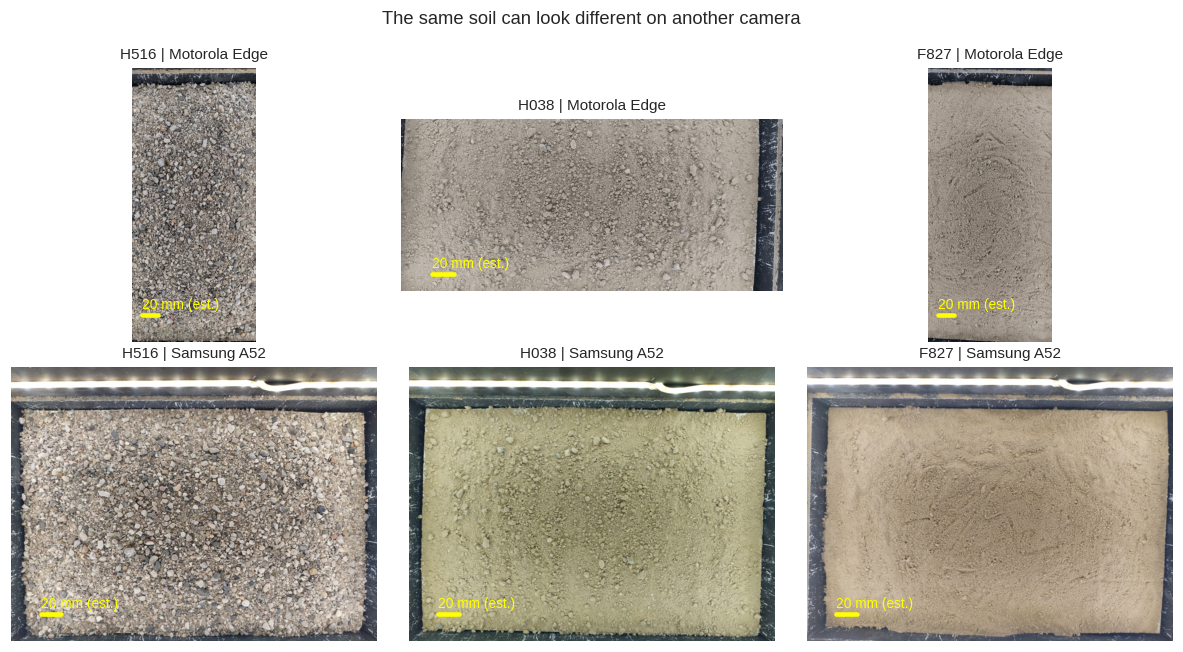

In [8]:
# Show up to two cameras for each example soil.
examples = []
for sample_id in example_ids:
    group = photos.query("split == 'train' and sample_id == @sample_id")
    examples.extend(group.drop_duplicates("device").head(2).to_dict("records"))

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, row in zip(axes.T.flat, examples):
    with Image.open(row["path"]) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        full_width = image.width
        image.thumbnail((640, 480))
    ax.imshow(image)
    bar_px = 20 * row["ppm_est"] * image.width / full_width
    x, y_bar = image.width * 0.08, image.height * 0.9
    ax.plot([x, x + bar_px], [y_bar, y_bar], color="yellow", linewidth=3)
    ax.text(x, y_bar - 10, "20 mm (est.)", color="yellow", fontsize=9)
    ax.set_title(row["sample_id"] + " | " + row["device"], fontsize=10)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("The same soil can look different on another camera")
fig.tight_layout()
plt.show()

## 5. Useful grain sizes

D10, D50, and D60 are sizes where 10%, 50%, and 60% of soil pass.
We find them between the known points on a log-size axis.
If a size is below the first point, we leave it empty. We do not guess it.

In [9]:
def grain_size(curve, percent):
    if percent < curve[0] or percent > curve[-1]:
        return np.nan
    right = np.searchsorted(curve, percent, side="left")
    if right == 0:
        return sieves[0]
    left = right - 1
    fraction = (percent - curve[left]) / (curve[right] - curve[left])
    return 10 ** (log_sieves[left] + fraction * (log_sieves[right] - log_sieves[left]))

grain_sizes = labels[["sample_id", "soil_group"]].copy()
for percent in [10, 50, 60]:
    grain_sizes[f"D{percent}_mm"] = [grain_size(curve, percent) for curve in y]
display(grain_sizes.groupby("soil_group")[["D10_mm", "D50_mm", "D60_mm"]].median().round(3))
print("Values below the measured size range:")
display(grain_sizes[["D10_mm", "D50_mm", "D60_mm"]].isna().sum().to_frame("count"))

,D10_mm,D50_mm,D60_mm
soil_group,,,
fine,0.004,0.030,0.044
gravel,0.097,4.585,6.961
sand,0.017,0.157,0.209


Values below the measured size range:


,count
D10_mm,1
D50_mm,0
D60_mm,0


## 6. Check the competition score

The score adds curve errors over ten log-size intervals. It uses the left point of each interval.
Lower is better. We use percent values, not values from 0 to 1.
The last point has no interval weight, but a valid curve must end at 100.

In [10]:
log_widths = np.diff(log_sieves)

def emd_per_sample(true, pred):
    true = np.asarray(true, dtype=float)
    pred = np.asarray(pred, dtype=float)
    assert true.shape == pred.shape and true.shape[-1] == len(sieves)
    return (np.abs(true - pred)[..., :-1] * log_widths).sum(axis=-1)

fine_curve = np.full(11, 100.0)
coarse_curve = np.r_[np.zeros(10), 100.0]
assert np.isclose(emd_per_sample(fine_curve, fine_curve), 0)
assert np.isclose(emd_per_sample(fine_curve, coarse_curve), 500)

one_error = coarse_curve.copy()
one_error[0] = 10
assert np.isclose(emd_per_sample(coarse_curve, one_error), 10 * log_widths[0])

# The last point is checked as a rule, not as an interval in the score.
wrong_end = fine_curve.copy()
wrong_end[-1] = 80
assert emd_per_sample(fine_curve, wrong_end) == 0
print("Metric checks passed: zero error, maximum 500, interval weight, and last point.")
print("A low score alone does not prove that a curve is valid.")

Metric checks passed: zero error, maximum 500, interval weight, and last point.
A low score alone does not prove that a curve is valid.


## 7. What can a scale error cost?

This is a curve test, not a model test. We make all grains 2x larger or smaller.
We shift each curve on the size axis. We use 0 and 100 outside the known range.
We set the last point to 100 so the new curve is valid.

,size_factor,mean_EMD,min_EMD,max_EMD
0,0.5,29.185,24.773,30.103
1,1.0,0.000,0.000,0.000
2,2.0,30.566,28.119,33.606


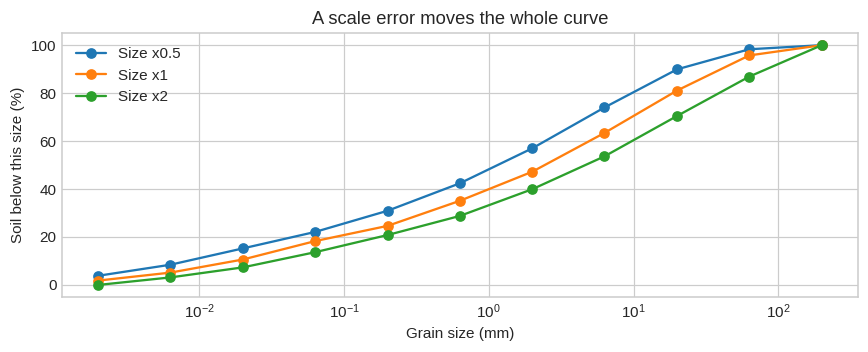

In [11]:
scale_scores = []
shifted_curves = {}
for factor in [0.5, 1.0, 2.0]:
    pred = np.array([np.interp(np.log10(sieves / factor), log_sieves, curve, left=0, right=100) for curve in y])
    pred[:, -1] = 100
    shifted_curves[factor] = pred
    error = emd_per_sample(y, pred)
    scale_scores.append({"size_factor": factor, "mean_EMD": error.mean(), "min_EMD": error.min(), "max_EMD": error.max()})
display(pd.DataFrame(scale_scores).round(3))

index = example_indices[1]
fig, ax = plt.subplots(figsize=(8, 3.3))
for factor, pred in shifted_curves.items():
    ax.semilogx(sieves, pred[index], marker="o", label=f"Size x{factor:g}")
ax.set(xlabel="Grain size (mm)", ylabel="Soil below this size (%)", title="A scale error moves the whole curve")
ax.legend()
fig.tight_layout()
plt.show()

## 8. Make safe folds

We split soil samples, then give each photo its sample fold.
No sample can be in train and validation at the same time.
We keep the same four folds for all later models.

In [12]:
N_FOLDS = 4
folds = labels[["sample_id", "soil_group"]].copy()
folds["fold"] = -1
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
assert folds.soil_group.value_counts().min() >= N_FOLDS
for fold, (_, valid_index) in enumerate(splitter.split(folds, folds.soil_group)):
    folds.loc[valid_index, "fold"] = fold

train_photos = photos.query("split == 'train'").merge(folds[["sample_id", "fold"]], on="sample_id", validate="many_to_one")
for fold in range(N_FOLDS):
    train_samples = set(train_photos.query("fold != @fold").sample_id)
    valid_samples = set(train_photos.query("fold == @fold").sample_id)
    assert train_samples.isdisjoint(valid_samples)
assert train_photos.groupby("sample_id").fold.nunique().eq(1).all()

# Show why a random photo split is unsafe.
train_part, valid_part = train_test_split(train_photos, test_size=0.25, random_state=SEED)
leaked = set(train_part.sample_id) & set(valid_part.sample_id)
print("Shared soil samples in a random photo split:", len(leaked))
print("Shared soil samples in our folds: 0")
display(pd.crosstab(folds.fold, folds.soil_group))
folds.to_csv(WORK_DIR / "sample_folds.csv", index=False)
train_photos.to_csv(WORK_DIR / "photo_folds.csv", index=False)

Shared soil samples in a random photo split: 19
Shared soil samples in our folds: 0


soil_group,fine,gravel,sand
fold,,,
0,2,2,2
1,2,3,1
2,2,3,1
3,1,3,2


## 9. Start with simple baselines

These baselines do not use images. Mean and median use only the train samples of each fold.
We score one curve per soil sample. More photos do not give a sample more weight.

In [13]:
oof = {name: np.zeros_like(y) for name in ["equal_bins", "train_mean", "train_median"]}
fold_id = folds.fold.to_numpy()
for fold in range(N_FOLDS):
    train_index = fold_id != fold
    valid_index = fold_id == fold
    oof["equal_bins"][valid_index] = np.arange(1, 12) / 11 * 100
    oof["train_mean"][valid_index] = y[train_index].mean(axis=0)
    oof["train_median"][valid_index] = np.median(y[train_index], axis=0)

fold_scores = []
for name, pred in oof.items():
    assert np.all(np.diff(pred, axis=1) >= -1e-6)
    assert np.allclose(pred[:, -1], 100)
    error = emd_per_sample(y, pred)
    for fold in range(N_FOLDS):
        fold_scores.append({"baseline": name, "fold": fold, "EMD": error[fold_id == fold].mean()})
    saved = pd.DataFrame(pred, columns=targets)
    saved.insert(0, "sample_id", labels.sample_id)
    saved.to_csv(WORK_DIR / f"oof_{name}.csv", index=False)

fold_scores = pd.DataFrame(fold_scores)
display(fold_scores.pivot(index="fold", columns="baseline", values="EMD").round(3))
display(fold_scores.groupby("baseline").EMD.agg(["mean", "std"]).round(3))
print("Std is the spread across four folds. It is not a confidence interval.")

baseline,equal_bins,train_mean,train_median
fold,,,
0,88.550,74.140,75.810
1,109.821,96.696,94.285
2,101.950,86.277,86.137
3,107.773,88.731,84.621


,mean,std
baseline,,
equal_bins,102.023,9.581
train_mean,86.461,9.341
train_median,85.213,7.570


Std is the spread across four folds. It is not a confidence interval.


## 10. Add a second score

We also report D10, D50, and D60 error on a log scale. This shows errors as size ratios.
We show the number of valid pairs, because some D10 values are below the known range.

One possible new score is the mean of EMD / 5 and the largest point error. Both parts have a range of 0 to 100.
It checks the full curve and gives more weight to a large local error. This is an idea to test, not the Kaggle score.

In [14]:
pred = oof["train_median"]
size_errors = []
for percent in [10, 50, 60]:
    true_size = np.array([grain_size(curve, percent) for curve in y])
    pred_size = np.array([grain_size(curve, percent) for curve in pred])
    valid = np.isfinite(true_size) & np.isfinite(pred_size)
    log_error = np.abs(np.log10(true_size[valid] / pred_size[valid]))
    size_errors.append({"size": f"D{percent}", "valid_pairs": valid.sum(), "skipped_pairs": (~valid).sum(),
                        "mean_abs_log10_error": log_error.mean(), "size_factor": 10 ** log_error.mean()})
display(pd.DataFrame(size_errors).round(3))

emd = emd_per_sample(y, pred).mean()
mae = np.abs(y - pred).mean()
print(f"Train-median OOF: EMD = {emd:.3f}, MAE = {mae:.3f}")
worst_point_error = np.abs(y - pred).max(axis=1).mean()
print(f"Mean largest point error = {worst_point_error:.3f}")
print(f"Proposed score = {(emd / 5 + worst_point_error) / 2:.3f}")

,size,valid_pairs,skipped_pairs,mean_abs_log10_error,size_factor
0,D10,23,1,0.687,4.867
1,D50,24,0,0.913,8.182
2,D60,24,0,0.942,8.744


Train-median OOF: EMD = 85.213, MAE = 15.493
Mean largest point error = 43.534
Proposed score = 30.288


## 11. Try tiles with the same size in mm

We start with 64 mm tiles and save them as 224 x 224 pixels.
This gives 3.5 pixels per mm for every camera. It covers more coarse grains than a small crop.
Very small grains are still too small to see. We must test other tile sizes later.

We cache three tiles from each train photo. We do not use test photos here.
Tiles still have one sample label. They are not new samples.

Cached tiles: 381 | Train photos: 127
Physical side range (mm): 63.9 to 64.02


,min_native_ppm
split,
test,13.94
train,4.55


Output pixels per mm: 3.5


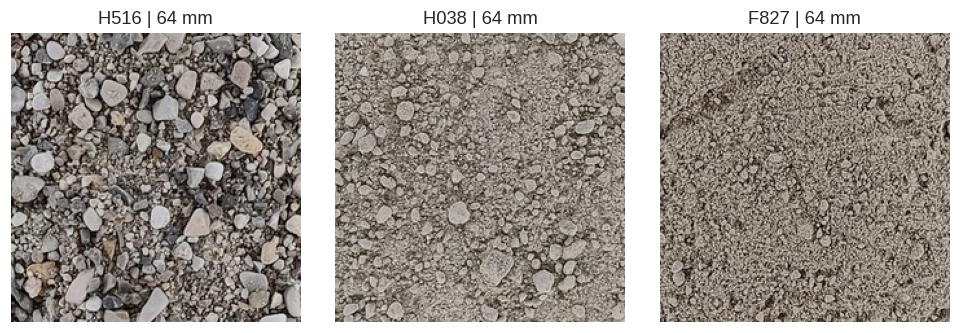

In [15]:
TILE_MM = 64
TILE_PX = 224
CACHE_DIR = WORK_DIR / f"tiles_{TILE_MM}mm_{TILE_PX}px"
CACHE_DIR.mkdir(exist_ok=True)
centres = [(0.4, 0.5), (0.5, 0.5), (0.6, 0.5)]

tile_rows = []
for row in train_photos.itertuples(index=False):
    crop_px = round(TILE_MM * row.ppm_est)
    with Image.open(row.path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        assert crop_px <= min(image.size)
        for tile_id, (cx, cy) in enumerate(centres):
            left = round(cx * image.width - crop_px / 2)
            top = round(cy * image.height - crop_px / 2)
            box = (left, top, left + crop_px, top + crop_px)
            assert left >= 0 and top >= 0 and box[2] <= image.width and box[3] <= image.height
            tile_path = CACHE_DIR / f"{Path(row.photo).stem}_{tile_id}.png"
            if not tile_path.exists():
                tile = image.crop(box).resize((TILE_PX, TILE_PX), Image.Resampling.LANCZOS)
                tile.save(tile_path)
            tile_rows.append({"sample_id": row.sample_id, "photo": row.photo, "fold": row.fold,
                              "tile_id": tile_id, "tile_path": str(tile_path), "crop_px": crop_px,
                              "ppm_est": row.ppm_est, "actual_tile_mm": crop_px / row.ppm_est})

tiles = pd.DataFrame(tile_rows)
assert tiles.groupby("sample_id").fold.nunique().eq(1).all()
tiles.to_csv(WORK_DIR / "tile_manifest.csv", index=False)
print("Cached tiles:", len(tiles), "| Train photos:", len(train_photos))
print("Physical side range (mm):", round(tiles.actual_tile_mm.min(), 2), "to", round(tiles.actual_tile_mm.max(), 2))
display(photos.groupby("split").ppm_est.min().to_frame("min_native_ppm").round(2))
print("Output pixels per mm:", TILE_PX / TILE_MM)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, sample_id in zip(axes, example_ids):
    row = tiles.query("sample_id == @sample_id and tile_id == 1").iloc[0]
    with Image.open(row.tile_path) as image:
        ax.imshow(image)
    ax.set_title(sample_id + " | 64 mm")
    ax.axis("off")
fig.tight_layout()
plt.show()

## 12. Check tile to sample scoring

First, average tile curves for each photo. Then, average photo curves for each soil sample.
This gives each photo the same weight, even if tile counts change.
Here we use the fold median as a fake tile prediction. This only checks the data flow.

In [16]:
tile_predictions = tiles[["sample_id", "photo", "fold"]].copy()
for column in targets:
    tile_predictions[column] = 0.0
for fold in range(N_FOLDS):
    curve = np.median(y[fold_id != fold], axis=0)
    tile_predictions.loc[tile_predictions.fold == fold, targets] = curve

photo_predictions = tile_predictions.groupby(["sample_id", "photo"])[targets].mean()
sample_predictions = photo_predictions.groupby("sample_id")[targets].mean().reindex(labels.sample_id)
assert np.allclose(sample_predictions.to_numpy(), oof["train_median"])
print("Tile -> photo -> sample check passed.")
print(f"Sample-level EMD: {emd_per_sample(y, sample_predictions.to_numpy()).mean():.3f}")
print("Files saved in:", WORK_DIR)

Tile -> photo -> sample check passed.
Sample-level EMD: 85.213
Files saved in: /kaggle/working/soil_eda


## Main points

- Train has 24 soil samples and 127 photos. Test has 10 samples and 35 photos.
- A random photo split shares 19 samples between train and validation.
- Test uses iPhones. Train uses Motorola and Samsung. Most train photos are about 1 to 2 MP.
- The PPM resize check is important. We must confirm the no-crop assumption.
- Photos show black tray edges and bright light spots. These can give a model false clues.
- Use the same sample folds and score one curve per sample.
- The test CSV has empty target values. They are not soil labels.
- The train-median baseline has OOF EMD 85.213. A 2x size shift gives mean EMD 30.566.
- A good next test is 32, 64, and 128 mm tiles on the same folds.

AI helped write and check this EDA. Read and check the code before using it in the full lab.